# Pronóstico de demanda de bicicletas públicas en Buenos Aires
**Mateo Taylor** · Proyecto de portfolio · Data Scientist

**Problema:** para que haya bicis disponibles donde y cuando se necesitan, el operador planifica la
redistribución de bicicletas y los turnos del personal **con un día de anticipación**. Si sobreestima la
demanda, desperdicia camiones y horas de trabajo; si la subestima, quedan estaciones vacías en hora pico.
Quiero un modelo que pronostique los **viajes por hora del día siguiente** usando el calendario y el
pronóstico del clima, y que sea claramente mejor que las reglas simples que se usan hoy.

> ⚠️ **Datos simulados** con `generar_datos.py`, inspirados en un sistema como EcoBici (2024–2025, viajes por
> hora + clima). No son datos oficiales. El notebook está preparado para reemplazarlos por los datos
> abiertos de viajes del GCBA y un histórico meteorológico con el mismo esquema.

**Contenido**
1. Exploración: ¿cuándo se usan las bicis?
2. Clima y calendario
3. Variables y partición temporal
4. Baselines vs. modelos
5. ¿Dónde se equivoca el modelo?
6. Escenarios: el efecto de la lluvia
7. Conclusiones

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer

VERDE, LIMA, GRIS, TINTA, ROJO, AZUL, OCRE = "#4f6b00", "#a6cf1f", "#9aa196", "#1d2219", "#c75b46", "#3f9c8f", "#d9a521"
plt.rcParams.update({
    "figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cec4",
    "xtick.color": "#5a6253", "ytick.color": "#5a6253", "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.titlepad": 12, "axes.grid": True, "grid.color": "#e6e9e1",
    "axes.axisbelow": True, "font.size": 10.5, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
SEED = 42
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

df = pd.read_csv("data/viajes_por_hora.csv.gz", parse_dates=["fecha_hora"])
df["fecha"] = df["fecha_hora"].dt.normalize(); df["hora"] = df["fecha_hora"].dt.hour
df["dia_semana"] = df["fecha_hora"].dt.dayofweek; df["mes"] = df["fecha_hora"].dt.month
df["no_laborable"] = (df["dia_semana"] >= 5) | df["feriado"]
print(f"{len(df):,} horas · {df['viajes'].sum():,} viajes · promedio {df.groupby('fecha')['viajes'].sum().mean():,.0f} viajes por día")
print("Horas faltantes:", pd.date_range(df["fecha_hora"].min(), df["fecha_hora"].max(), freq="h").difference(df["fecha_hora"]).size)
df.head()

17,544 horas · 18,516,003 viajes · promedio 25,330 viajes por día
Horas faltantes: 0


,fecha_hora,viajes,temperatura_c,lluvia_mm,humedad_pct,viento_kmh,feriado,fecha,hora,dia_semana,mes,no_laborable
0,2024-01-01 00:00:00,63,21.40,0.00,66,16.90,True,2024-01-01,0,0,1,True
1,2024-01-01 01:00:00,99,21.00,0.00,65,8.50,True,2024-01-01,1,0,1,True
2,2024-01-01 02:00:00,86,20.10,0.00,76,21.40,True,2024-01-01,2,0,1,True
3,2024-01-01 03:00:00,84,18.90,0.00,62,8.60,True,2024-01-01,3,0,1,True
4,2024-01-01 04:00:00,82,20.20,0.00,60,6.50,True,2024-01-01,4,0,1,True


## 1. Exploración: ¿cuándo se usan las bicis?

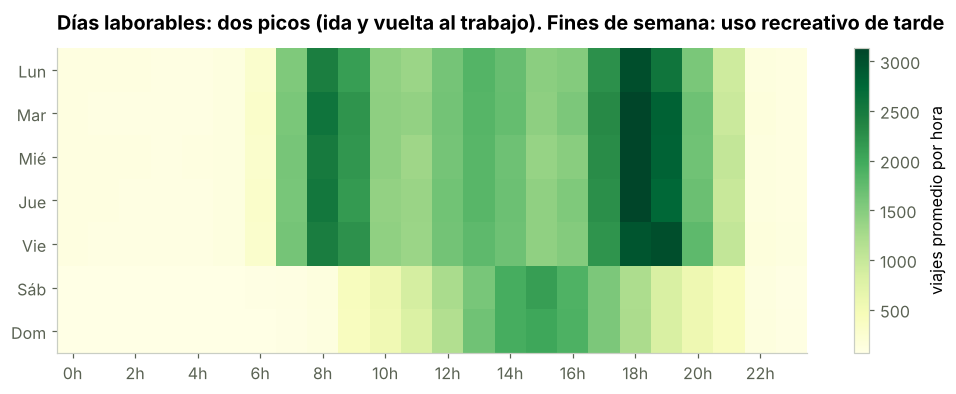

In [2]:
mapa = df.pivot_table(index="dia_semana", columns="hora", values="viajes", aggfunc="mean")
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(mapa.values, aspect="auto", cmap="YlGn")
ax.set_yticks(range(7), DIAS); ax.set_xticks(range(0, 24, 2), [f"{x}h" for x in range(0, 24, 2)]); ax.grid(False)
plt.colorbar(im, ax=ax, label="viajes promedio por hora")
ax.set_title("Días laborables: dos picos (ida y vuelta al trabajo). Fines de semana: uso recreativo de tarde")
plt.show()

Viajes 2025 vs 2024: +12.2%


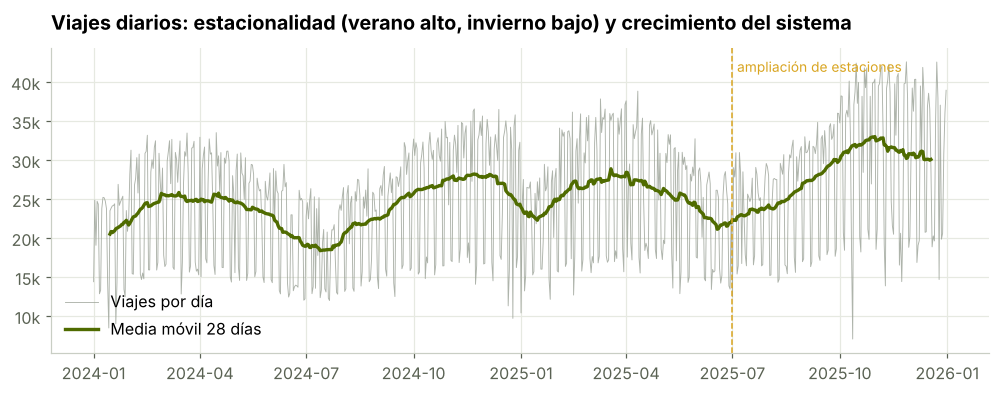

In [3]:
diario = df.groupby("fecha").agg(viajes=("viajes", "sum"), temp=("temperatura_c", "mean"), lluvia=("lluvia_mm", "sum"),
                                  no_laborable=("no_laborable", "first"))
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(diario.index, diario["viajes"], color=GRIS, lw=.6, alpha=.8, label="Viajes por día")
ax.plot(diario.index, diario["viajes"].rolling(28, center=True).mean(), color=VERDE, lw=2.2, label="Media móvil 28 días")
ax.axvline(pd.Timestamp("2025-07-01"), color=OCRE, ls="--", lw=1); ax.text(pd.Timestamp("2025-07-05"), diario["viajes"].max() * .97, "ampliación de estaciones", color=OCRE, fontsize=9)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k")); ax.legend(loc="lower left")
ax.set_title("Viajes diarios: estacionalidad (verano alto, invierno bajo) y crecimiento del sistema")
plt.show()
crec = diario.loc["2025", "viajes"].sum() / diario.loc["2024", "viajes"].sum() - 1
print(f"Viajes 2025 vs 2024: {crec:+.1%}")

## 2. Clima y calendario
Comparo la demanda en horas equivalentes (mismo tipo de día y franja horaria) para aislar el efecto del clima.

Con lluvia fuerte la demanda cae al 34% de lo normal; con llovizna, al 75%.


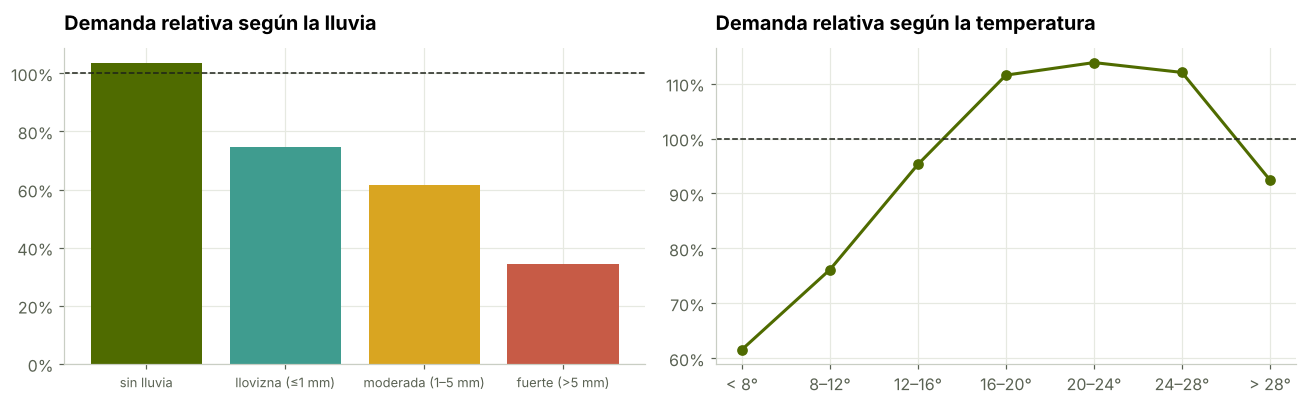

In [4]:
df["franja"] = pd.cut(df["hora"], [-1, 6, 10, 16, 20, 23], labels=["madrugada", "pico mañana", "mediodía", "pico tarde", "noche"])
base = df.groupby(["no_laborable", "franja"], observed=True)["viajes"].transform("mean")
df["indice"] = df["viajes"] / base
df["tramo_lluvia"] = pd.cut(df["lluvia_mm"], [-.1, 0, 1, 5, 100], labels=["sin lluvia", "llovizna (≤1 mm)", "moderada (1–5 mm)", "fuerte (>5 mm)"])
lluvia_ef = df.groupby("tramo_lluvia", observed=True)["indice"].mean()
df["tramo_temp"] = pd.cut(df["temperatura_c"], [-5, 8, 12, 16, 20, 24, 28, 40], labels=["< 8°", "8–12°", "12–16°", "16–20°", "20–24°", "24–28°", "> 28°"])
temp_ef = df.groupby("tramo_temp", observed=True)["indice"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(lluvia_ef.index.astype(str), lluvia_ef.values, color=[VERDE, AZUL, OCRE, ROJO])
axes[0].axhline(1, color=TINTA, ls="--", lw=1); axes[0].set_title("Demanda relativa según la lluvia")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].tick_params(axis="x", labelsize=8.5)
axes[1].plot(temp_ef.index.astype(str), temp_ef.values, "o-", color=VERDE, lw=2)
axes[1].axhline(1, color=TINTA, ls="--", lw=1); axes[1].set_title("Demanda relativa según la temperatura")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.tight_layout(); plt.show()
print(f"Con lluvia fuerte la demanda cae al {lluvia_ef.iloc[-1]:.0%} de lo normal; con llovizna, al {lluvia_ef.iloc[1]:.0%}.")

In [5]:
cal = diario.assign(tipo=np.where(diario.index.dayofweek >= 5, "Fin de semana",
                                  np.where(diario["no_laborable"], "Feriado en día hábil", "Día hábil")))
cal["enero"] = diario.index.month == 1
tabla_cal = cal.groupby(["tipo"])["viajes"].mean().to_frame("viajes por día")
tabla_cal.loc["Día hábil de enero (vacaciones)"] = cal.loc[(cal["tipo"] == "Día hábil") & cal["enero"], "viajes"].mean()
tabla_cal

,viajes por día
tipo,
Día hábil,"29,873.18"
Feriado en día hábil,"15,936.26"
Fin de semana,"15,982.56"
Día hábil de enero (vacaciones),"25,020.73"


## 3. Variables y partición temporal
El pronóstico se hace **el día anterior**, así que solo puedo usar información disponible en ese momento:
- **calendario**: hora, día de la semana, mes, feriado, vacaciones;
- **pronóstico del clima** (en el histórico uso el clima observado como aproximación);
- **historia de la demanda**: el mismo horario una semana antes y el promedio de ese horario en los
  últimos 7 días. Nunca uso datos del mismo día que estoy pronosticando.

Entreno con enero 2024 – agosto 2025 y evalúo con **septiembre – diciembre 2025** (4 meses que el modelo no vio).

In [6]:
df = df.sort_values("fecha_hora").reset_index(drop=True)
df["lag_semana"] = df["viajes"].shift(168)
# promedio de la misma hora en los 7 días anteriores (el pronóstico se arma al cierre del día previo)
df["media_7d_misma_hora"] = df.groupby("hora")["viajes"].transform(lambda s: s.shift(1).rolling(7).mean())
df["lluvia_si"] = (df["lluvia_mm"] > 0).astype(int)
df["vacaciones"] = ((df["mes"] == 1) | ((df["mes"] == 7) & df["fecha_hora"].dt.day.between(15, 28))).astype(int)
df["feriado"] = df["feriado"].astype(int); df["no_laborable"] = df["no_laborable"].astype(int)
df["dias_desde_inicio"] = (df["fecha_hora"] - df["fecha_hora"].min()).dt.days

NUM = ["temperatura_c", "lluvia_mm", "humedad_pct", "viento_kmh", "lag_semana", "media_7d_misma_hora", "dias_desde_inicio"]
BIN = ["feriado", "no_laborable", "lluvia_si", "vacaciones"]
CAT = ["hora", "dia_semana", "mes"]
FEATS = NUM + BIN + CAT
datos = df.dropna(subset=["lag_semana", "media_7d_misma_hora"]).copy()
train = datos[datos["fecha_hora"] < "2025-09-01"]; test = datos[datos["fecha_hora"] >= "2025-09-01"]
print(f"Entrenamiento: {len(train):,} horas ({train['fecha_hora'].min():%d/%m/%Y} – {train['fecha_hora'].max():%d/%m/%Y})")
print(f"Prueba: {len(test):,} horas ({test['fecha_hora'].min():%d/%m/%Y} – {test['fecha_hora'].max():%d/%m/%Y})")

Entrenamiento: 14,448 horas (08/01/2024 – 31/08/2025)
Prueba: 2,928 horas (01/09/2025 – 31/12/2025)


## 4. Baselines vs. modelos
Un modelo solo vale la pena si le gana a las reglas simples. Comparo:
- **Baseline 1, "igual que la semana pasada":** misma hora, mismo día de la semana anterior.
- **Baseline 2, "promedio histórico":** promedio de esa hora y ese día de la semana en el entrenamiento.
- **Regresión Ridge** con splines de temperatura y variables de calendario.
- **Gradient boosting** (`HistGradientBoostingRegressor` con pérdida de Poisson, adecuada para conteos).

Métricas: **MAE** (error absoluto medio, en viajes por hora) y **WAPE** (error total como % de la demanda total),
que es fácil de explicar al negocio.

In [7]:
def metricas(y, p):
    return {"MAE": np.mean(np.abs(y - p)), "RMSE": np.sqrt(np.mean((y - p) ** 2)), "WAPE": np.abs(y - p).sum() / y.sum()}

y_test = test["viajes"].values
pred = {}
pred["Igual que la semana pasada"] = test["lag_semana"].values
prom = train.groupby(["dia_semana", "hora"])["viajes"].mean()
pred["Promedio histórico"] = prom.reindex(pd.MultiIndex.from_arrays([test["dia_semana"], test["hora"]])).values

ridge = make_pipeline(ColumnTransformer([
    ("temp", SplineTransformer(n_knots=6, degree=3), ["temperatura_c"]),
    ("num", StandardScaler(), [c for c in NUM if c != "temperatura_c"] + BIN),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)]), Ridge(alpha=3.0))
ridge.fit(train[FEATS], train["viajes"]); pred["Regresión Ridge"] = np.clip(ridge.predict(test[FEATS]), 0, None)

gbm = HistGradientBoostingRegressor(loss="poisson", learning_rate=.06, max_iter=600, max_leaf_nodes=48, min_samples_leaf=30,
                                    l2_regularization=1.0, categorical_features=[FEATS.index(c) for c in CAT], random_state=SEED)
gbm.fit(train[FEATS], train["viajes"]); pred["Gradient boosting"] = gbm.predict(test[FEATS])

res = pd.DataFrame({k: metricas(y_test, v) for k, v in pred.items()}).T.sort_values("MAE")
res["mejora vs. semana pasada"] = 1 - res["MAE"] / res.loc["Igual que la semana pasada", "MAE"]
res

,MAE,RMSE,WAPE,mejora vs. semana pasada
Gradient boosting,204.75,350.87,0.16,0.39
Regresión Ridge,334.09,486.76,0.26,0.00
Igual que la semana pasada,334.58,580.91,0.26,0.00
Promedio histórico,358.48,576.85,0.28,-0.07


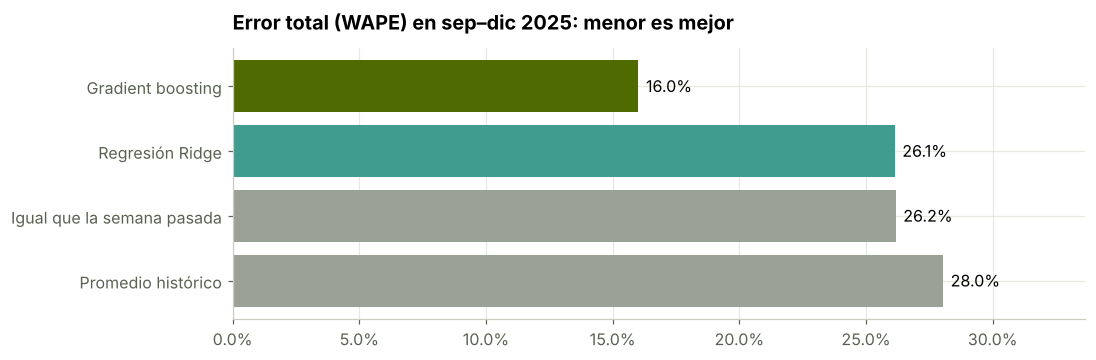

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.2))
r = res.sort_values("WAPE", ascending=False)
COL = {"Gradient boosting": VERDE, "Regresión Ridge": AZUL}
ax.barh(r.index, r["WAPE"], color=[COL.get(n, GRIS) for n in r.index])
for i, v in enumerate(r["WAPE"]): ax.text(v + .003, i, f"{v:.1%}", va="center")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlim(0, r["WAPE"].max() * 1.2)
ax.set_title("Error total (WAPE) en sep–dic 2025: menor es mejor")
plt.show()

Semana elegida: 06/10 – 12/10/2025


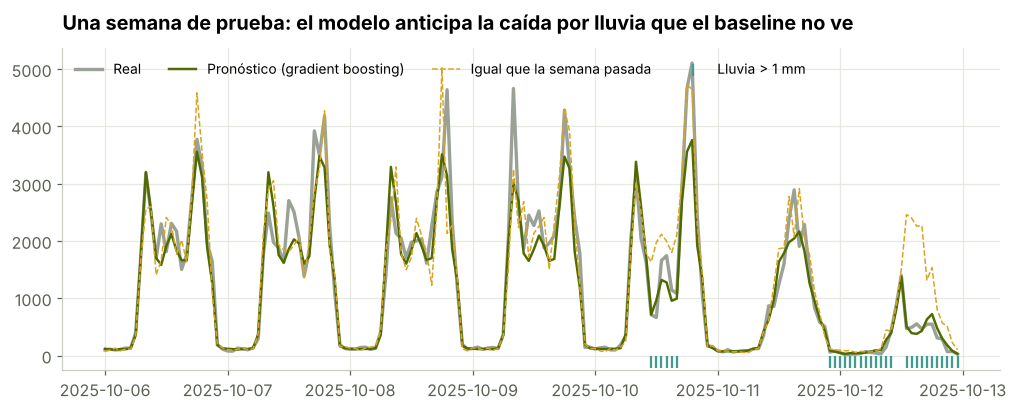

In [9]:
# elijo la semana de prueba con más lluvia en horario de uso (de lunes a domingo)
lluvia_dia = test[test["hora"].between(7, 21)].groupby("fecha")["lluvia_mm"].sum()
lunes = (lluvia_dia.idxmax() - pd.Timedelta(days=lluvia_dia.idxmax().dayofweek))
lunes = min(max(lunes, pd.Timestamp("2025-09-01")), pd.Timestamp("2025-12-22"))
sem = test[(test["fecha_hora"] >= lunes) & (test["fecha_hora"] < lunes + pd.Timedelta(days=7))]
print(f"Semana elegida: {lunes:%d/%m} – {lunes + pd.Timedelta(days=6):%d/%m/%Y}")
ps = pd.Series(pred["Gradient boosting"], index=test.index).loc[sem.index]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(sem["fecha_hora"], sem["viajes"], color=GRIS, lw=2.2, label="Real")
ax.plot(sem["fecha_hora"], ps, color=VERDE, lw=1.6, label="Pronóstico (gradient boosting)")
ax.plot(sem["fecha_hora"], sem["lag_semana"], color=OCRE, lw=1, ls="--", label="Igual que la semana pasada")
llueve = sem[sem["lluvia_mm"] > 1]
ax.scatter(llueve["fecha_hora"], np.full(len(llueve), -120), marker="|", color=AZUL, s=60, label="Lluvia > 1 mm")
ax.legend(loc="upper left", ncol=4, fontsize=9); ax.set_ylim(-250, None)
ax.set_title("Una semana de prueba: el modelo anticipa la caída por lluvia que el baseline no ve")
plt.show()

## 5. ¿Dónde se equivoca el modelo?

In [10]:
test = test.assign(pred=pred["Gradient boosting"], error_abs=np.abs(test["viajes"] - pred["Gradient boosting"]),
                   error_base=np.abs(test["viajes"] - test["lag_semana"]))
por_lluvia = test.groupby("tramo_lluvia", observed=True).apply(
    lambda g: pd.Series({"horas": len(g), "WAPE modelo": g["error_abs"].sum() / g["viajes"].sum(),
                         "WAPE semana pasada": g["error_base"].sum() / g["viajes"].sum()}), include_groups=False)
por_lluvia

,horas,WAPE modelo,WAPE semana pasada
tramo_lluvia,,,
sin lluvia,"2,686.00",0.16,0.23
llovizna (≤1 mm),20.00,0.18,0.34
moderada (1–5 mm),135.00,0.22,0.71
fuerte (>5 mm),87.00,0.19,1.69


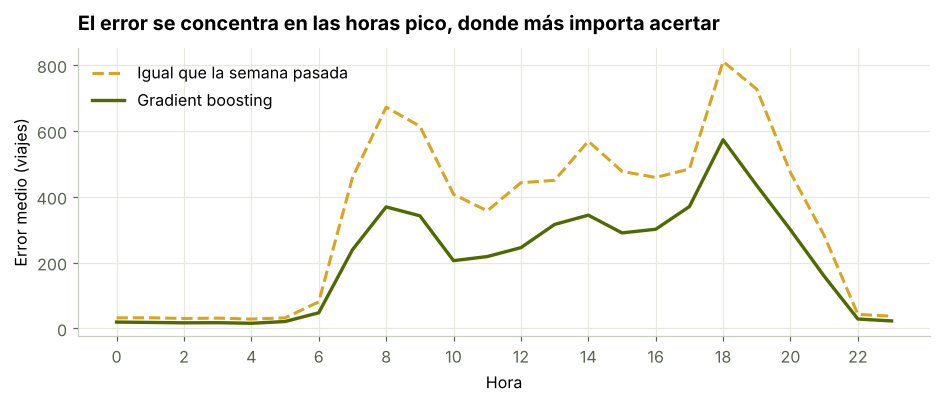

In [11]:
por_hora = test.groupby("hora").apply(lambda g: pd.Series({"MAE modelo": g["error_abs"].mean(), "MAE semana pasada": g["error_base"].mean()}), include_groups=False)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(por_hora.index, por_hora["MAE semana pasada"], color=OCRE, lw=2, ls="--", label="Igual que la semana pasada")
ax.plot(por_hora.index, por_hora["MAE modelo"], color=VERDE, lw=2.2, label="Gradient boosting")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hora"); ax.set_ylabel("Error medio (viajes)"); ax.legend()
ax.set_title("El error se concentra en las horas pico, donde más importa acertar")
plt.show()

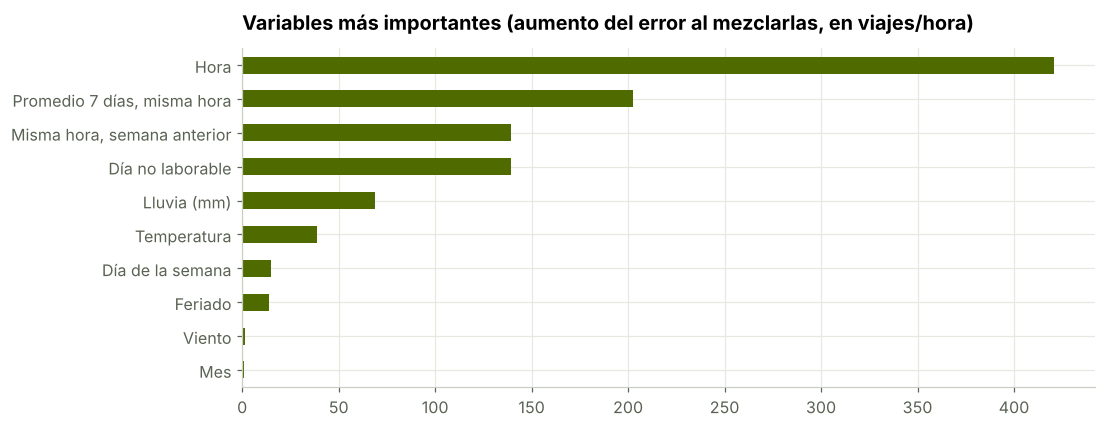

In [12]:
pi = permutation_importance(gbm, test[FEATS], y_test, scoring="neg_mean_absolute_error", n_repeats=4, random_state=SEED, n_jobs=-1)
NOMBRES = {"temperatura_c": "Temperatura", "lluvia_mm": "Lluvia (mm)", "humedad_pct": "Humedad", "viento_kmh": "Viento",
           "lag_semana": "Misma hora, semana anterior", "media_7d_misma_hora": "Promedio 7 días, misma hora", "dias_desde_inicio": "Tendencia",
           "feriado": "Feriado", "no_laborable": "Día no laborable", "lluvia_si": "Llueve (sí/no)", "vacaciones": "Vacaciones",
           "hora": "Hora", "dia_semana": "Día de la semana", "mes": "Mes"}
imp = pd.Series(pi.importances_mean, index=[NOMBRES[f] for f in FEATS]).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4))
imp.head(10)[::-1].plot.barh(ax=ax, color=VERDE)
ax.set_title("Variables más importantes (aumento del error al mezclarlas, en viajes/hora)")
plt.show()

## 6. Escenarios: el efecto de la lluvia
Con el modelo puedo responder preguntas de planificación. Por ejemplo: **¿cuántos viajes se pierden en un
día hábil de octubre si llueve toda la tarde?** Comparo el pronóstico del mismo día con y sin lluvia.

Viajes del día: seco 34,382 · con lluvia 25,059 (27% menos; 52% menos durante la tarde)


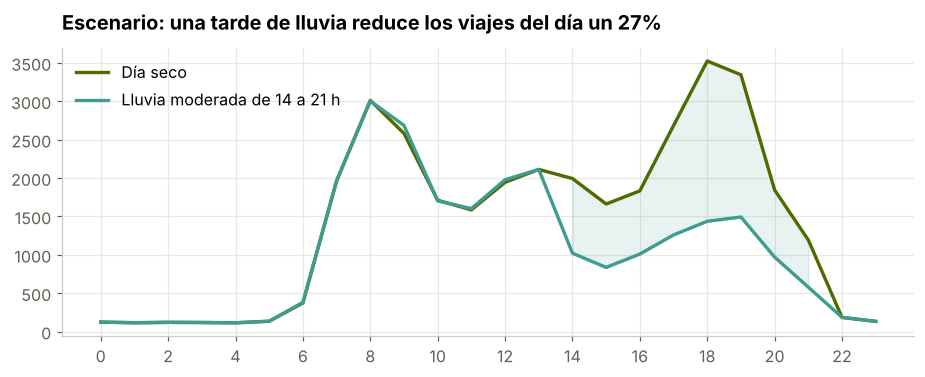

In [13]:
dia = test[test["fecha"] == "2025-10-15"].copy()  # un miércoles hábil típico de primavera
seco = dia.copy(); seco[["lluvia_mm", "lluvia_si"]] = 0; seco["humedad_pct"] = 62
lluv = dia.copy(); tarde = lluv["hora"].between(14, 21)
lluv.loc[tarde, "lluvia_mm"] = 4.0; lluv.loc[tarde, "lluvia_si"] = 1; lluv.loc[tarde, "humedad_pct"] = 90
p_seco, p_lluv = gbm.predict(seco[FEATS]), gbm.predict(lluv[FEATS])
perdida = 1 - p_lluv.sum() / p_seco.sum(); perdida_tarde = 1 - p_lluv[tarde.values].sum() / p_seco[tarde.values].sum()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(dia["hora"], p_seco, color=VERDE, lw=2.2, label="Día seco"); ax.plot(dia["hora"], p_lluv, color=AZUL, lw=2.2, label="Lluvia moderada de 14 a 21 h")
ax.fill_between(dia["hora"], p_lluv, p_seco, where=tarde.values, color=AZUL, alpha=.12)
ax.set_xticks(range(0, 24, 2)); ax.legend(); ax.set_title(f"Escenario: una tarde de lluvia reduce los viajes del día un {perdida:.0%}")
plt.show()
print(f"Viajes del día: seco {p_seco.sum():,.0f} · con lluvia {p_lluv.sum():,.0f} ({perdida:.0%} menos; {perdida_tarde:.0%} menos durante la tarde)")

In [14]:
# mismos escenarios con distintas intensidades (para el dashboard)
escenarios = {}
for nombre, mm in [("llovizna", 0.8), ("moderada", 4.0), ("fuerte", 10.0)]:
    e = dia.copy(); e.loc[tarde, "lluvia_mm"] = mm; e.loc[tarde, "lluvia_si"] = 1; e.loc[tarde, "humedad_pct"] = 90
    pe = gbm.predict(e[FEATS]); escenarios[nombre] = {"mm": mm, "pred": np.round(pe).tolist(), "perdida": float(1 - pe.sum() / p_seco.sum())}
pd.DataFrame({k: {"lluvia de 14 a 21 h (mm/h)": v["mm"], "viajes del día": sum(v["pred"]), "caída vs. día seco": v["perdida"]} for k, v in escenarios.items()}).T

,lluvia de 14 a 21 h (mm/h),viajes del día,caída vs. día seco
llovizna,0.80,"29,353.00",0.15
moderada,4.00,"25,058.00",0.27
fuerte,10.00,"21,709.00",0.37


## 7. Conclusiones
**Lo que muestran los datos**
1. **El sistema crece:** 25.000 viajes por día en promedio, un 12 % más en 2025, con un salto después de la ampliación de estaciones de julio.
2. **Dos usos distintos:** los días hábiles tienen picos de ida y vuelta al trabajo (8 y 18 h), con casi 30.000 viajes. Los fines de semana y feriados tienen la mitad (≈16.000), concentrados en la tarde. En las vacaciones de enero, los días hábiles caen un 16 %.
3. **El clima pesa mucho.** Con lluvia fuerte la demanda cae al 34 % de lo normal, y con llovizna al 75 %. Bajo los 8 °C se usa un 38 % menos, y también baja con más de 28 °C.
4. **Gradient boosting reduce el error un 39 %** frente a la regla "igual que la semana pasada": WAPE de 16 % contra 26 % en cuatro meses no vistos. La regresión lineal no mejora al baseline, porque los efectos del clima y el horario se multiplican y un modelo lineal no los captura.
5. **La mayor ventaja está en los días de lluvia:** con lluvia fuerte, el error del modelo es 19 % contra 169 % del baseline, que "espera" la demanda de una semana seca.
6. **Escenario:** una tarde de lluvia moderada en un día hábil de octubre baja los viajes del día un 27 % (52 % durante la tarde).

**Cómo lo usaría la operación**
- **Planificar la redistribución con el pronóstico del día siguiente:** menos camiones y personal los días de lluvia o frío, y refuerzo en los picos de 8 y 18 h de los días hábiles.
- **Alertas automáticas** cuando el pronóstico del clima anticipe lluvia en hora pico, para reasignar turnos con tiempo.
- **Planificar el mantenimiento** de bicis y estaciones en las franjas y temporadas de menor demanda (madrugada, invierno, vacaciones de enero).

**Próximos pasos:** pronosticar por estación (no solo el total del sistema) para decidir dónde llevar las bicis, usar el pronóstico meteorológico real en lugar del clima observado y sumar intervalos de predicción (por ejemplo, con regresión por cuantiles) para planificar con un margen de seguridad.

In [15]:
lab_sem = [d.strftime("%Y-%m-%dT%H") for d in sem["fecha_hora"]]
out = {
    "kpis": {"viajes_dia": float(diario["viajes"].mean()), "crec": float(crec), "pico": float(mapa.values.max()),
             "lluvia_fuerte": float(lluvia_ef.iloc[-1]), "perdida_escenario": float(perdida)},
    "mapa": {"valores": np.round(mapa.values).tolist()},
    "diario": {"fechas": [d.strftime("%Y-%m-%d") for d in diario.index[::7]],
               "media": diario["viajes"].rolling(28, center=True).mean().iloc[::7].round(0).replace({np.nan: None}).tolist(),
               "viajes": diario["viajes"].iloc[::7].tolist()},
    "lluvia": {"labels": [str(x) for x in lluvia_ef.index], "valores": lluvia_ef.round(4).tolist()},
    "temp": {"labels": [str(x) for x in temp_ef.index], "valores": temp_ef.round(4).tolist()},
    "modelos": res.reset_index(names="modelo").to_dict("records"),
    "semana": {"labels": lab_sem, "real": sem["viajes"].tolist(), "pred": ps.round(0).tolist(), "base": sem["lag_semana"].round(0).tolist(),
               "lluvia": sem["lluvia_mm"].tolist()},
    "por_hora": {"modelo": por_hora["MAE modelo"].round(1).tolist(), "base": por_hora["MAE semana pasada"].round(1).tolist()},
    "por_lluvia": por_lluvia.reset_index().to_dict("records"),
    "importancia": [{"variable": k, "valor": float(v)} for k, v in imp.head(10).items()],
    "escenario": {"seco": np.round(p_seco).tolist(), "lluvia": np.round(p_lluv).tolist(), "perdida": float(perdida), "perdida_tarde": float(perdida_tarde), "intensidades": escenarios},
    "calendario": {k: float(v) for k, v in tabla_cal["viajes por día"].items()},
}
dest = Path("../../bicis"); dest.mkdir(parents=True, exist_ok=True)
(dest / "data.json").write_text(json.dumps(out, ensure_ascii=False, default=float))
print("Datos del dashboard exportados:", dest / "data.json")

Datos del dashboard exportados: ../../bicis/data.json
